# One combined missing / special matrix as input

Earlier notebooks received two indicator matrices: `missing` (0/1) and `special` (codes 1..K). This notebook uses **one combined matrix** instead, in the coding of your data:

| code | meaning |
|---|---|
| 0 | regular (observed) value |
| 1 | missing |
| 2 … 8 | special value 1 … 7 |

**What stays the same.** The model already works with exactly this coding internally, so nothing in the model changes:
* **One learned embedding per code**, shared by all variables and time steps: `nn.Embedding(9, state_emb_dim)` for codes 0–8.
* **Early fusion** (the default here): every cell becomes `e(v,t) = 1[code=0]·(w·x+b) + E[code]`. The cells of a sliding patch are concatenated into a token, attention runs across variables and then across time, and the time-series CLS is concatenated with the snapshot CLS before the head.
* **Late fusion** (`FUSION = "late"` below) gives the original three-CLS design: the code embeddings go through their own encoder, and that CLS is concatenated with the time-series and snapshot CLS tokens.

**What changes: memory.** The combined matrix is stored as `uint8`, 1 byte per cell. Preprocessing now works through the records in chunks, and can write its output into the input arrays (`inplace=True`) or read them memory-mapped from disk.

| bytes per cell | before (separate float32 + int64 matrices, whole-array preprocessing) | now (combined uint8, chunked) |
|---|---|---|
| raw input | 16 (x 4 + missing 4 + special 8) | **5** (x 4 + state 1) |
| extra while preprocessing | 36 for the whole split | **0** in place / **5** for a new output, plus < 1 GB for one chunk |
| processed data kept for training | 5 | 5 |

Section 4 measures this on the demo data and projects it to 2M + 1M records × 11 steps × 460 variables.

In [1]:
import sys, math, tracemalloc, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO))
from tsfusion import (ModelConfig, TrainConfig, RawData, Preprocessor, Trainer, TSFusionTransformer,
                      long_df_to_array, group_columns_by_prefix, default_target_mode, load_checkpoint,
                      predict_with, regression_metrics, count_parameters, save_dataset, load_dataset)
from tsfusion import interpret as I
from tsfusion import viz as Z
from tsfusion.synthetic import make_synthetic_dataset

Z.use_style()
HAS_GPU = torch.cuda.is_available()
DEVICE = "cuda:0" if HAS_GPU else "cpu"
SMALL = not HAS_GPU
FUSION = "early"                      # "late" = three CLS tokens; same combined input either way
RUNS = REPO / "runs" / "demo_combined_state"
print("torch", torch.__version__, "| device", DEVICE)

torch 2.15.0+cu132 | device cpu


## 1. Data as delivered

These are synthetic records in the same layout as your data: a long time-series frame and **one** state frame with the same index and columns, plus the PLE snapshot frame and the target. There are 7 special values, so the codes run from 0 to 8.

In [2]:
K = 7                                                     # special values -> codes 2..8
data = make_synthetic_dataset(n_records=6000, n_vars=8, n_special_codes=K, seed=0)
ts_df, state_df = data["ts_df"], data["state_df"]
snapshot_ple_df, y = data["snapshot_ple_df"], data["y"]
train_ids, val_ids, var_names, time_steps = data["train_ids"], data["val_ids"], data["var_names"], data["time_steps"]

code_names = {0: "regular", 1: "missing", **{c: f"special {c - 1} (code {c})" for c in range(2, K + 2)}}
counts = pd.Series(state_df.values.ravel()).value_counts().sort_index()
print(pd.DataFrame({"meaning": [code_names[c] for c in counts.index], "cells": counts.values,
                    "share %": (100 * counts / counts.sum()).round(2).values}, index=counts.index).to_string())

rid = next(r for r in train_ids if (state_df.loc[r].values >= 2).sum() >= 2 and (state_df.loc[r].values == 1).sum() >= 2)
pd.concat({"value": ts_df.loc[rid].round(1), "state": state_df.loc[rid]}, axis=1).iloc[:, [0, 1, 2, 3, 8, 9, 10, 11]]

              meaning   cells  share %
0             regular  429644    81.37
1             missing   65607    12.43
2  special 1 (code 2)    4582     0.87
3  special 2 (code 3)    6029     1.14
4  special 3 (code 4)    4515     0.86
5  special 4 (code 5)    4562     0.86
6  special 5 (code 6)    4338     0.82
7  special 6 (code 7)    4301     0.81
8  special 7 (code 8)    4422     0.84


value                       state                     
          var_00 var_01 var_02 var_03 var_00 var_01 var_02 var_03
time_step                                                        
1         -189.7  368.7 -993.0 -340.7      0      0      2      0
2         -475.5  204.4  -87.4 -159.9      0      0      0      0
3         -554.4  343.1   68.1 -125.1      0      0      0      0
4         -544.5  259.6  109.6 -159.9      0      0      0      0
5            0.0  184.6  462.7 -209.6      1      0      0      0
6         -109.4  190.1  183.5 -296.2      0      0      0      0
7           21.2  191.9  202.5 -220.7      0      0      0      0
8          -21.6  319.4  219.4 -216.9      0      0      0      0
9          150.0  273.1 -996.0 -342.1      0      0      5      0
10         212.9  347.3  558.3 -233.5      0      0      0      0
11         317.2  149.9  566.6  -91.9      0      0      0      0

## 2. From DataFrames to arrays

There are two arrays per split, with the same record order:

| array | shape | dtype | bytes per cell |
|---|---|---|---|
| `x` | `(N, T, V)` | float32 | 4 |
| `state` | `(N, T, V)` | **uint8** | 1 |

`long_df_to_array(state_df, dtype=np.uint8, fill_value=1)` builds the state matrix. A record with fewer than 11 time steps gets code 1 (missing) for the absent rows.

In [3]:
ple_groups = group_columns_by_prefix(snapshot_ple_df.columns)
ple_cols = [c for _, cols in ple_groups for c in cols]
group_sizes = [len(cols) for _, cols in ple_groups]

def to_raw(ids) -> RawData:
    kw = dict(value_cols=var_names, record_ids=ids, time_steps=time_steps)
    x, _ = long_df_to_array(ts_df, **kw)                                    # float32
    state, _ = long_df_to_array(state_df, dtype=np.uint8, fill_value=1, **kw)   # uint8, one matrix
    return RawData(x, state=state, snapshot=snapshot_ple_df.loc[ids, ple_cols].to_numpy(),
                   y=y.loc[ids].to_numpy())

train_raw, val_raw = to_raw(train_ids), to_raw(val_ids)
pd.DataFrame({name: [a.shape, a.dtype, f"{a.nbytes / 2**20:.1f} MB"]
              for name, a in [("x", train_raw.x), ("state", train_raw.state),
                              ("snapshot", train_raw.snapshot), ("y", train_raw.y)]},
             index=["shape (train)", "dtype", "memory"])

,x,state,snapshot,y
shape (train),"(4800, 11, 8)","(4800, 11, 8)","(4800, 42)","(4800,)"
dtype,float32,uint8,float32,float64
memory,1.6 MB,0.4 MB,0.8 MB,0.0 MB


**Optional: hand the arrays over through files.** `save_dataset` writes plain `.npy` files. `load_dataset(..., mmap=True)` memory-maps them: nothing is read into RAM until the preprocessor processes it, chunk by chunk. This is how `scripts/train.py` reads data, and it is how you would hand arrays from a Spark job to the training notebook.

In [4]:
DATA_DIR = RUNS / "prepared"
save_dataset(str(DATA_DIR), {"train": train_raw, "val": val_raw}, n_special_codes=K,
             snapshot_group_sizes=group_sizes)
splits, meta = load_dataset(str(DATA_DIR), mmap=True)
print(sorted(p.name for p in DATA_DIR.iterdir()))
print("state is a read-only view onto the file:", not splits["train"].state.flags.owndata,
      "| codes 0..", int(splits["train"].state.max()))

['meta.json', 'train_snapshot.npy', 'train_state.npy', 'train_x.npy', 'train_y.npy', 'val_snapshot.npy', 'val_state.npy', 'val_x.npy', 'val_y.npy']
state is a read-only view onto the file: True | codes 0.. 8


## 3. Preprocessing the combined matrix

The steps are the same as before, applied directly to the codes:
1. `x` is standardised per variable, with mean and std computed over **cells with code 0 only**. The chunked computation gives exactly the result of a single pass.
2. Values are clipped to ±10, and every cell with a code ≠ 0 is set to 0. The model never reads those values; it reads the code's embedding.
3. A NaN or inf in `x` at a code-0 cell becomes code 1 (missing).
4. Codes are checked: anything outside `0 … K+1` raises an error that explains the expected coding, as shown below.

`fit` and `transform` work in chunks (about 50M cells each by default; `chunk_size=` sets it in records). `transform(..., inplace=True)` writes the processed values into the input arrays and returns tensors that share their memory. Use it when you no longer need the raw values.

In [5]:
prep = Preprocessor(n_special_codes=K, snapshot_group_sizes=group_sizes,
                    target_mode=default_target_mode("tweedie")).fit(train_raw)
print("per-variable mean (regular cells):", np.round(prep.ts_mean[:4], 1), "...")

bad = to_raw(train_ids[:50]); bad.state[0, 0, 0] = 9
try:
    prep.transform(bad)
except ValueError as e:
    print("code check ->", e)

per-variable mean (regular cells): [ 34.7 440.4 637.7 279.8] ...
code check -> state code 9 found, but with n_special_codes=7 the codes must be 0 (regular), 1 (missing) or 2..8 (special)


## 4. Memory: measured here, projected to your data

The cell below measures the extra memory each step allocates, on the demo training split, for three ways of running `transform`:
* **new output:** the raw arrays stay intact and a new processed copy is made;
* **in place:** the processed values overwrite the raw arrays;
* **from disk:** the raw arrays are memory-mapped files, and the processed copy is in RAM.

The demo data is small enough to fit in one default chunk (about 50M cells), so `chunk_size=500` records is used here to make it span several chunks, as large data does. The table splits each peak into three parts:
* **new processed arrays:** 5 bytes per cell; none when working in place;
* **snapshot:** small;
* **chunk working memory:** set by the chunk size and independent of the number of records; under 1 GB at the default chunk size.

The projection below is therefore `5 bytes × cells` for each copy of the data that has to exist, plus one chunk.

In [6]:
def extra_peak(fn):
    tracemalloc.start(); tracemalloc.reset_peak()
    base, _ = tracemalloc.get_traced_memory()
    out = fn()
    _, peak = tracemalloc.get_traced_memory(); tracemalloc.stop()
    return out, peak - base

cells, CH = train_raw.x.size, 500
_, m_fit = extra_peak(lambda: Preprocessor(K, group_sizes, target_mode="mean_scale").fit(train_raw, chunk_size=CH))
_, m_new = extra_peak(lambda: prep.transform(train_raw, chunk_size=CH))
copy_raw = RawData(train_raw.x.copy(), state=train_raw.state.copy(), snapshot=train_raw.snapshot, y=train_raw.y)
_, m_inp = extra_peak(lambda: prep.transform(copy_raw, inplace=True, chunk_size=CH))
_, m_mm = extra_peak(lambda: prep.transform(splits["train"], chunk_size=CH))
MB = 2 ** 20
new_arrays = 5 * cells                              # processed x (4 B) + state (1 B) per cell
snap = 2 * train_raw.snapshot.nbytes                # snapshot: converted + packed (small)
tab = pd.DataFrame({"extra peak": [m_fit, m_new, m_inp, m_mm],
                    "new processed arrays": [0, new_arrays, 0, new_arrays],
                    "snapshot": [0, snap, snap, snap]},
                   index=["fit", "transform: new output", "transform: in place", "transform: from disk (mmap)"])
tab["chunk working memory"] = tab["extra peak"] - tab["new processed arrays"] - tab["snapshot"]
(tab / MB).round(2).add_suffix(" (MB)")

,extra peak (MB),new processed arrays (MB),snapshot (MB),chunk working memory (MB)
fit,0.72,0.00,0.00,0.72
transform: new output,3.94,2.01,1.54,0.39
transform: in place,1.80,0.00,1.54,0.26
transform: from disk (mmap),3.94,2.01,1.54,0.38


In [7]:
def project(n_train, n_val, T=11, V=460, n_snap=10, bins=10, chunk_gb=1.0):
    c_tr, c_va = n_train * T * V, n_val * T * V
    gb = 1e9
    proc = 5 * (c_tr + c_va) / gb + (n_train + n_val) * n_snap * bins * 4 / gb   # x + state + snapshot
    raw = proc                                                                     # same 5 B/cell
    rows = {
        "in place (raw arrays become the processed data)": proc + chunk_gb,
        "from disk (mmap raw, processed copy in RAM)":     proc + chunk_gb,
        "new output, both raw splits in RAM":               raw + 5 * c_tr / gb + chunk_gb,
        "previous version (separate float32/int64 matrices)": 16 * (c_tr + c_va) / gb + 36 * c_tr / gb,
    }
    return pd.Series(rows, name="peak RAM (GB)").round(0)

print("2,000,000 train + 1,000,000 holdout records x 11 steps x 460 variables; training itself needs",
      f"~{5 * 3e6 * 11 * 460 / 1e9 + 1.2:.0f} GB (processed train + holdout)")
project(2_000_000, 1_000_000).to_frame()

2,000,000 train + 1,000,000 holdout records x 11 steps x 460 variables; training itself needs ~77 GB (processed train + holdout)


,peak RAM (GB)
in place (raw arrays become the processed data),78.0
"from disk (mmap raw, processed copy in RAM)",78.0
"new output, both raw splits in RAM",129.0
previous version (separate float32/int64 matrices),607.0


## 5. How the combined codes reach the model

The sliding patches cut the value matrix and the code matrix identically. Each cell is then looked up in the **one** embedding table, which has rows 0–8:

In [8]:
train = prep.transform(train_raw)
val = prep.transform(val_raw)
model_cfg = ModelConfig(n_vars=len(var_names), n_steps=11, n_special_codes=K, snapshot_group_sizes=group_sizes,
                        patch_len=3, patch_stride=1, state_emb_dim=16, d_model=32 if SMALL else 64,
                        ff_mult=2 if SMALL else 4, n_heads=4, n_ts_layers=2, missing_fusion=FUSION)
torch.manual_seed(42)                               # reproducible initial weights
model = TSFusionTransformer(model_cfg)
table = (model.value_embed if FUSION != "late" else model.state_embed).state_emb
print(f"fusion={FUSION}: state embedding table {tuple(table.weight.shape)} = {model_cfg.n_states} codes x "
      f"{model_cfg.state_emb_dim} dims, shared by all {len(var_names)} variables; model {count_parameters(model):,} parameters")

rec = list(train_ids).index(rid)
v = int(np.argmax((train_raw.state[rec] != 0).sum(0)))    # variable with most non-regular cells
sp = model.patcher(train.state[rec:rec + 1].long())[0, v]
pd.DataFrame({"patch": [f"t{1 + i}..t{i + 3}" for i in range(model.n_patches)],
              "codes in the patch": [s.tolist() for s in sp],
              "embedding rows looked up": [[code_names[int(c)].split(" (")[0] for c in s] for s in sp]}).set_index("patch")

fusion=early: state embedding table (9, 16) = 9 codes x 16 dims, shared by all 8 variables; model 47,089 parameters


,codes in the patch,embedding rows looked up
patch,,
t1..t3,"[1, 1, 1]","[missing, missing, missing]"
t2..t4,"[1, 1, 1]","[missing, missing, missing]"
t3..t5,"[1, 1, 1]","[missing, missing, missing]"
t4..t6,"[1, 1, 1]","[missing, missing, missing]"
t5..t7,"[1, 1, 1]","[missing, missing, missing]"
t6..t8,"[1, 1, 1]","[missing, missing, missing]"
t7..t9,"[1, 1, 1]","[missing, missing, missing]"
t8..t10,"[1, 1, 0]","[missing, missing, regular]"
t9..t11,"[1, 0, 8]","[missing, regular, special 7]"


## 6. Training

The training loop is the same as in notebooks 01 and 03: per-epoch metrics on the original scale, a checkpoint every epoch, the best model selected by validation RMSE, and early stopping. The loss is Tweedie with p = 1.5.

In [9]:
steps = math.ceil(len(train) / 256)
train_cfg = TrainConfig(loss="tweedie", tweedie_power=1.5, batch_size=256, max_epochs=40 if SMALL else 150,
                        lr=1e-3, warmup_steps=2 * steps, early_stopping_patience=8, device=DEVICE,
                        train_eval_max_samples=2000, output_dir=str(RUNS / f"{FUSION}_tweedie"), seed=42)
trainer = Trainer(model_cfg, train_cfg, prep, model=model)
hist = trainer.fit(train, val)
hist[["epoch", "lr", "train_loss", "val_loss", "train_rmse", "val_rmse", "val_r2", "val_mae", "val_nmad", "is_best"]].round(4).tail(6)

14:56:36 | removed 29 files of a previous run in /home/user/RI/runs/demo_combined_state/early_tweedie


14:56:36 | device=cpu amp=off params=47,089 train=4,800 val=1,200 loss=tweedie(p=1.5) fusion=early


14:56:36 | data: 3.7 MiB (train + val), kept on CPU


14:56:41 | epoch   1 | lr 5.00e-04 | train loss 3.9978 rmse 5083.8239 mae 2483.0583 r2 0.0129 nmad 1223.1632 | val loss 4.1652 rmse 5911.8312 mae 2700.0738 r2 0.0098 nmad 1270.1357 | *best* | 4.7s


14:56:45 | epoch   2 | lr 1.00e-03 | train loss 3.8418 rmse 4565.0553 mae 1840.4155 r2 0.2041 nmad 975.7069 | val loss 3.9225 rmse 5306.4011 mae 1993.9573 r2 0.2022 nmad 1009.3924 | *best* | 4.8s


14:56:50 | epoch   3 | lr 1.00e-03 | train loss 3.6921 rmse 4350.2266 mae 1740.3833 r2 0.2772 nmad 907.5938 | val loss 3.7240 rmse 5074.4656 mae 1857.7041 r2 0.2704 nmad 875.2927 | *best* | 4.8s


... (35 outputs left out)

14:59:53 | epoch  39 | lr 1.25e-04 | train loss 3.5125 rmse 3263.0043 mae 1543.1435 r2 0.5933 nmad 932.0143 | val loss 3.6329 rmse 4413.3467 mae 1795.2137 r2 0.4481 nmad 1010.5847 | *best* | 5.5s


14:59:58 | epoch  40 | lr 1.25e-04 | train loss 3.5153 rmse 3275.5638 mae 1479.6905 r2 0.5902 nmad 870.4912 | val loss 3.6352 rmse 4439.7982 mae 1742.8216 r2 0.4415 nmad 964.9023 | 1 bad | 5.1s


14:59:58 | restored best model from epoch 39 (val RMSE 4413.3467)


,epoch,lr,train_loss,val_loss,train_rmse,val_rmse,val_r2,val_mae,val_nmad,is_best
34,35,0.0001,3.5153,3.6409,3284.6859,4474.4620,0.4327,1727.9499,933.6117,False
35,36,0.0001,3.5143,3.6342,3262.6339,4424.3302,0.4454,1781.2361,956.1069,True
36,37,0.0001,3.5150,3.6323,3242.8591,4427.3106,0.4446,1779.4893,976.6364,False
37,38,0.0001,3.5137,3.6340,3242.7028,4448.2155,0.4394,1759.9690,987.9778,False
38,39,0.0001,3.5125,3.6329,3263.0043,4413.3467,0.4481,1795.2137,1010.5847,True
39,40,0.0001,3.5153,3.6352,3275.5638,4439.7982,0.4415,1742.8216,964.9023,False


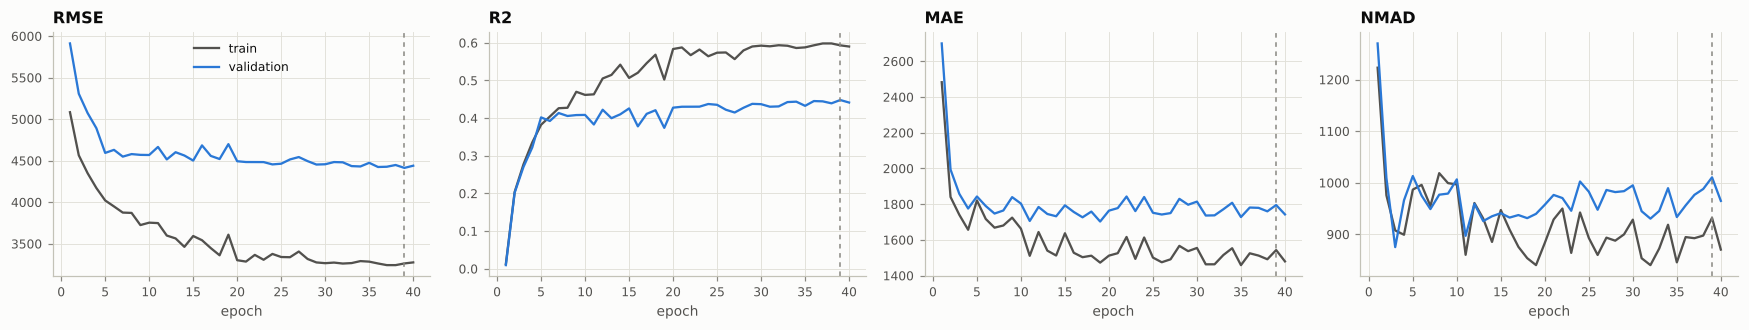

best epoch 39: {'rmse': 4413.347, 'mae': 1795.214, 'r2': 0.448, 'nmad': 1010.585}


In [10]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.1))
for ax, m in zip(axes, ["rmse", "r2", "mae", "nmad"]):
    ax.plot(hist.epoch, hist[f"train_{m}"], label="train", color=Z.INK2)
    ax.plot(hist.epoch, hist[f"val_{m}"], label="validation", color=Z.MISSING)
    ax.axvline(hist.loc[hist.val_rmse.idxmin(), "epoch"], color=Z.MUTED, ls=(0, (3, 3)), lw=1)
    ax.set_title(m.upper(), loc="left"); ax.set_xlabel("epoch"); ax.grid(True); ax.set_axisbelow(True)
axes[0].legend(); plt.tight_layout(); plt.show()

best_model, best_prep, best_cfg, ckpt = load_checkpoint(str(Path(train_cfg.output_dir) / "best_model.pt"))
pred = predict_with(best_model, best_prep, best_cfg, best_prep.transform(val_raw))
print(f"best epoch {ckpt['epoch']}:", {k: round(v, 3) for k, v in regression_metrics(val_raw.y, pred).items()})

## 7. What the model learned for each code

Each code has one learned vector. The similarity map shows which codes the model treats alike, and the probe shows what switching regular cells to each code does to the predictions. In this synthetic data only *special 2 (code 3)* has a direct effect on the target (its share raises the target), and *missing* is more frequent for riskier records. The other special codes carry no signal, which makes them a useful reference for noise-level effects.

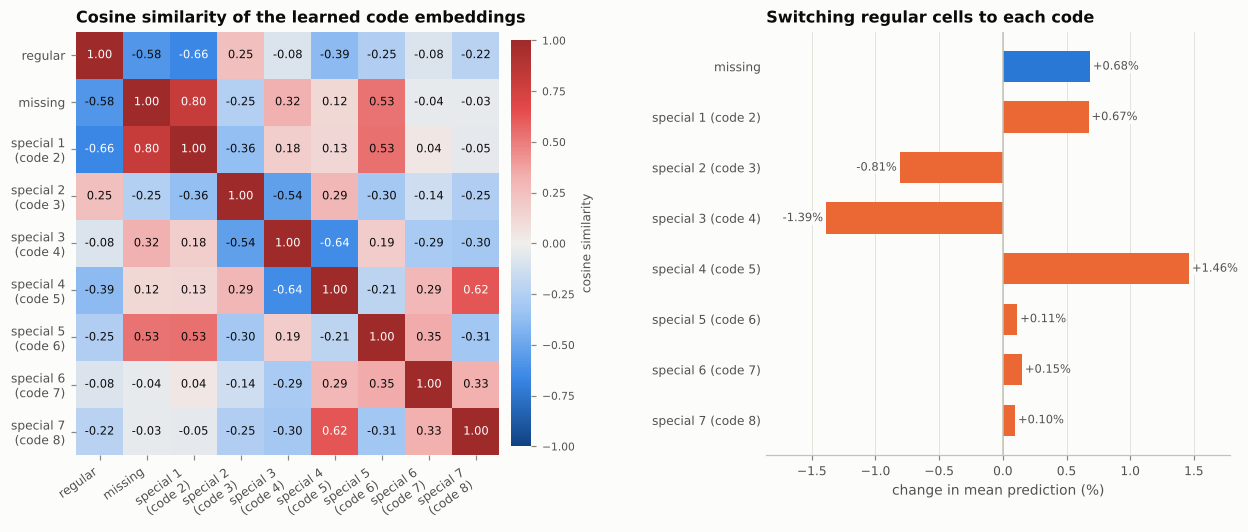

In [11]:
names = [code_names[c].replace(" (code", "\n(code") for c in range(model_cfg.n_states)]
sim = I.state_similarity(best_model); sim.index = sim.columns = names
probe = I.state_probe(best_model, best_prep.transform(val_raw), best_prep, best_cfg, n_cells=600)
fig = plt.figure(figsize=(15, 5))
gs = fig.add_gridspec(1, 2, width_ratios=[1.25, 1], wspace=0.45)
Z.plot_similarity(fig, fig.add_subplot(gs[0]), sim, "Cosine similarity of the learned code embeddings")
Z.plot_hbar(fig.add_subplot(gs[1]), [code_names[c] for c in probe.code], probe.mean_prediction_change_pct,
            colors=[Z.state_color(int(c)) for c in probe.code], fmt="{:+.2f}%",
            title="Switching regular cells to each code", xlabel="change in mean prediction (%)")
plt.show()

**What this run shows.** The demo is too small to learn what 7 rare codes mean:
* **Missing** moves predictions up (+0.7%), in the expected direction: riskier records have more gaps in the generator.
* **The special codes** move predictions between −1.4% and +1.5% in a pattern unrelated to the generator. *Special 2 (code 3)*, the only code with a real effect, *lowers* predictions (−0.8%) when it should raise them. Codes with no effect at all move them by similar amounts.
* **The similarity map** groups some codes, for example *missing* with *special 1* (0.80) and *special 4* with *special 7* (0.62), but nothing in the data gives those pairs a shared meaning.
* **Why:** each special code covers about 1% of cells, which is roughly 3,500–5,000 training cells per code in 4,800 records. That is not enough to separate 7 codes, so their vectors still largely reflect random initialisation and noise.

On your data, a code covering 1% of cells occurs about 100 million times in 2M training records, so this is a limitation of the demo size. The same two views are how to check your trained model: a code whose probe effect contradicts what it means is a candidate for merging with a similar code, or for stronger regularisation.

## 8. Checklist for your data

1. **Coding.** Use 0 regular, 1 missing, 2..K+1 special, with `n_special_codes = K` (7 for codes 2–8). Codes must be consecutive, and an unused code just gets an embedding that is never trained.
2. **Data types.** Use `x` as float32 and `state` as uint8. In Spark, `.cast("tinyint")` and then `.astype(np.uint8)` in numpy. `RawData` warns if `state` uses more than 1 byte per cell.
3. **Lowest-memory recipe:**
   ```python
   prep = Preprocessor(n_special_codes=7, snapshot_group_sizes=group_sizes, target_mode="mean_scale").fit(train_raw)
   train = prep.transform(train_raw, inplace=True)   # train_raw is consumed
   val   = prep.transform(val_raw,   inplace=True)
   ```
   Or save once with `save_dataset` and train from memory-mapped files (`load_dataset(dir, mmap=True)`, which `scripts/train.py` uses).
4. **Size.** About 77 GB of RAM for 2M + 1M × 11 × 460 (section 4). The data is far above 30% of a 40 GB GPU, so the trainer streams it batch by batch.
5. **Fusion.** `missing_fusion="early"` (this notebook) or `"late"` (three CLS tokens). Both take the same combined matrix.